# MU projekat

Skup podataka: [Kaggle – Credit Card Transactions Fraud Detection](https://www.kaggle.com/datasets/kartik2112/fraud-detection)

## 1.1 Odabir i učitavanje skupa podataka

Tema je detekcija prevarnih transakcija kao **nadzirana binarna klasifikacija**. Cilj je `is_fraud`: **0 = legitimna, 1 = prevarna transakcija**.

Podaci s Kagglea su **simulirani alatom Sparkov**. Originalne datoteke su `fraudTrain.csv` i `fraudTest.csv`; u ovom notebooku učitavamo tri ranije sačuvana uzorka iz `fraudTrain.csv`.

**Status rada:** završeni su odabir i učitavanje (1.1), istraživačka analiza (1.3) i priprema podataka (1.4). Pregled naučnih radova (1.2) nalazi se u Overleaf dokumentaciji. Izgradnja modela (zadatak 2) još slijedi. Balansirani uzorak služi samo EDA analizi; trening, validacijski i testni skup formiraju se u odjeljku 1.4 iz `fraud_50k.csv`.

In [1]:
import os
# import kagglehub
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
# Prikaz na dvije decimale, bez naučnog zapisa; izvorne vrijednosti ostaju iste.
pd.set_option('display.float_format', '{:.2f}'.format)
pd.set_option('display.width', 200)

## Preuzimanje skupa podataka (zakomentarisano)
Originalni skup je preuzet sa Kaggle-a pomoću `kagglehub` i balansiran (ćelije ispod). Rezultat je sačuvan u `fraud_balanced.csv`,
pa ovi koraci nisu potrebni pri svakom pokretanju – ostavljeni su kao referenca kako je CSV nastao.

In [2]:
# # Download latest version
# path = kagglehub.dataset_download("kartik2112/fraud-detection")
#
# print("Path to dataset files:", path)
# print(os.listdir(path))

In [3]:
# train = pd.read_csv(os.path.join(path, 'fraudTrain.csv'), index_col=0)
# test = pd.read_csv(os.path.join(path, 'fraudTest.csv'), index_col=0)
#
# print('train:', train.shape)
# print('test: ', test.shape)

In [4]:
# train.head()

## Balansiranje skupa (undersampling)
Skup je jako nebalansiran (~0.58 % prevara). Zadržavamo sve prevare i nasumično biramo isti broj transakcija koje nisu prevara, tako da odnos bude 50/50.

Ovo dokumentuje ranije formiranje uzorka za EDA. Za modeliranje (odjeljak 1.4) prvo se razdvajaju nebalansirani podaci, a balansiranje se primjenjuje samo na trening dio.

In [5]:
# print('Prije balansiranja:')
# print(train['is_fraud'].value_counts())
#
# fraud = train[train['is_fraud'] == 1]
# not_fraud = train[train['is_fraud'] == 0].sample(n=len(fraud), random_state=42)
#
# train_bal = pd.concat([fraud, not_fraud]).sample(frac=1, random_state=42).reset_index(drop=True)
#
# print('\nPoslije balansiranja:')
# print(train_bal['is_fraud'].value_counts())
# print((train_bal['is_fraud'].value_counts(normalize=True) * 100).round(2).astype(str) + ' %')
# print('\ntrain_bal:', train_bal.shape)
#
# train_bal.to_csv('fraud_balanced.csv', index=False)

## Smanjeni skupovi sa originalnim odnosom (stratifikovani uzorak)
Nasumično biramo 15 000 i 50 000 transakcija iz `fraudTrain.csv`, zadržavajući originalni odnos prevara / nije prevara (~0.58 %).

In [6]:
# def stratifikovani_uzorak(N):
#     n_fraud = round(N * train['is_fraud'].mean())
#     fraud = train[train['is_fraud'] == 1].sample(n=n_fraud, random_state=42)
#     not_fraud = train[train['is_fraud'] == 0].sample(n=N - n_fraud, random_state=42)
#     return pd.concat([fraud, not_fraud]).sample(frac=1, random_state=42).reset_index(drop=True)
#
# for N, ime in [(15000, 'fraud_15k.csv'), (50000, 'fraud_50k.csv')]:
#     uzorak = stratifikovani_uzorak(N)
#     print(ime, uzorak.shape, uzorak['is_fraud'].value_counts().to_dict())
#     uzorak.to_csv(ime, index=False)

## Učitavanje sačuvanih skupova
- `fraud_balanced.csv` – sve prevare iz `fraudTrain.csv` + isti broj nasumično odabranih transakcija koje nisu prevara (50/50)
- `fraud_15k.csv` – 15 000 nasumičnih transakcija sa originalnim odnosom (~0.58 % prevara)
- `fraud_50k.csv` – 50 000 nasumičnih transakcija sa originalnim odnosom (~0.58 % prevara); iz njega se u 1.4 formiraju trening, validacijski i testni skup

In [7]:
text_columns = [
    'trans_date_trans_time', 'cc_num', 'merchant', 'category',
    'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
    'job', 'dob', 'trans_num'
]
read_types = {c: 'string' for c in text_columns}

df = pd.read_csv('fraud_balanced.csv', dtype=read_types)

print('df:', df.shape)
print(df['is_fraud'].value_counts())
df.head()

df: (15012, 22)
is_fraud
1    7506
0    7506
Name: count, dtype: int64


,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,state,zip,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2020-06-01 01:01:21,565399283797,fraud_Koepp-Witting,grocery_pos,312.81,Anthony,Allen,M,6993 Carr Lodge Apt. 311,Jordan Valley,OR,97910,42.88,-117.28,641,Economist,1993-11-24,c48f2efccb689f2daef9ebdb03e1edec,1370048481,42.66,-117.72,1
1,2019-09-12 12:49:41,4683638447911,fraud_Bogisich-Homenick,misc_net,909.75,Daniel,Boyd,M,8925 Nicholas Points,Egan,LA,70531,30.25,-92.50,1261,Broadcast presenter,1972-07-01,68f2b98cba5c4ae6b7ff3f701d0cdc69,1347454181,30.62,-91.52,1
2,2019-10-05 17:08:54,3520550088202337,fraud_Bechtelar-Rippin,food_dining,7.59,Micheal,Walters,M,15315 Vaughn Park Suite 356,Hovland,MN,55606,47.83,-90.05,272,Freight forwarder,2001-07-05,b832170811fa7ce7ec76d9af27adecd2,1349456934,48.08,-89.63,0
3,2019-09-05 13:34:08,343746486082492,fraud_Kilback Group,food_dining,3.41,Jeffrey,Munoz,M,836 Stephanie Union,Cedar,MI,49621,44.86,-85.81,3096,"Social research officer, government",1975-10-11,7bbb699e093e3fb7d16c96093e95d66f,1346852048,45.48,-86.14,0
4,2019-01-22 23:04:30,344709867813900,fraud_Gottlieb-Hansen,personal_care,17.52,Joanna,Hudson,F,2924 Bobby Trafficway,Sebring,FL,33872,27.47,-81.49,50835,Environmental consultant,1986-01-30,5666921b2c9a994021da1bdbb9aea908,1327273470,27.69,-81.09,1


In [8]:
df_15k = pd.read_csv('fraud_15k.csv', dtype=read_types)

print('df_15k:', df_15k.shape)
print(df_15k['is_fraud'].value_counts())
print((df_15k['is_fraud'].value_counts(normalize=True) * 100).round(2).astype(str) + ' %')

df_15k: (15000, 22)
is_fraud
0    14913
1       87
Name: count, dtype: int64
is_fraud
0    99.42 %
1     0.58 %
Name: proportion, dtype: str


In [9]:
df_50k = pd.read_csv('fraud_50k.csv', dtype=read_types)

print('df_50k:', df_50k.shape)
print(df_50k['is_fraud'].value_counts())
print((df_50k['is_fraud'].value_counts(normalize=True) * 100).round(2).astype(str) + ' %')

df_50k: (50000, 22)
is_fraud
0    49711
1      289
Name: count, dtype: int64
is_fraud
0    99.42 %
1     0.58 %
Name: proportion, dtype: str


## 1.3 Istraživačka analiza podataka

Cilj je upoznati podatke prije pravljenja modela. Želimo odgovoriti na pet pitanja:
1. Šta predstavlja svaka kolona i jesu li podaci potpuni?
2. Koliko imamo legitimnih transakcija i prevara?
3. Koje su vrijednosti uobičajene, a koje se izdvajaju?
4. Kako se legitimne transakcije i prevare razlikuju po iznosu, vremenu i kategoriji?
5. Koje kolone nose slične informacije?

**Jedan red je jedna transakcija.** Analiziramo svih 22 originalna atributa iz fraud_balanced.csv. Kolona **is_fraud** je cilj: 0 znači legitimna transakcija, 1 znači prevara.

Svaki dio prati isti red: pitanje → računanje i prikaz → objašnjenje rezultata. Sve tabele, grafikoni i zaključci prikazani su u ovom notebooku.

In [10]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
os.environ.setdefault('MPLCONFIGDIR', '/tmp/mu-matplotlib')
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Važi i kada se EDA dio pokrene zasebno.
pd.set_option('display.float_format', '{:.2f}'.format)

ROOT = Path.cwd()
if not (ROOT / 'fraud_balanced.csv').exists():
    raise FileNotFoundError('U radni direktorij učitati fraud_balanced.csv, fraud_15k.csv i fraud_50k.csv.')
# Sve tekstualne kolone učitavamo kao string; numeričke zadržavaju svoje tipove.
text_columns = [
    'trans_date_trans_time', 'cc_num', 'merchant', 'category',
    'first', 'last', 'gender', 'street', 'city', 'state', 'zip',
    'job', 'dob', 'trans_num'
]
read_types = {c: 'string' for c in text_columns}
sources = {name: pd.read_csv(ROOT / name, dtype=read_types)
           for name in ['fraud_balanced.csv', 'fraud_15k.csv', 'fraud_50k.csv']}
raw = sources['fraud_balanced.csv']
eda = raw.copy(deep=True)
original_columns = list(raw.columns)
continuous = ['amt', 'lat', 'long', 'city_pop', 'unix_time', 'merch_lat', 'merch_long']
categorical = ['cc_num', 'merchant', 'category', 'first', 'last', 'gender',
               'street', 'city', 'state', 'zip', 'job', 'trans_num']
semantic = {c: 'kategorički' for c in categorical}
semantic.update({c: 'numerički' for c in continuous})
semantic.update({'cc_num': 'identifikator kartice', 'trans_num': 'identifikator transakcije',
                 'zip': 'kategorički (poštanski broj)', 'unix_time': 'numerički (vrijeme)',
                 'trans_date_trans_time': 'datum/vrijeme', 'dob': 'datum',
                 'is_fraud': 'binarna ciljna klasa'})
sns.set_theme(style='whitegrid', palette=['#168B90', '#C46535'], font_scale=1.1)
plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 180, 'axes.titleweight': 'bold'})
CLASS = {0: 'Legitimna (0)', 1: 'Prevarna (1)'}
COLORS = {0: '#168B90', 1: '#C46535'}
# Isti grafikoni prikazuju se ovdje i spremaju za Overleaf izvještaj.
FIGURE_DIR = ROOT / 'overleaf' / 'slike'
def show_plot(fig, filename):
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURE_DIR / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

# Nazive kolona čuvamo kao u datasetu, a opis pomaže pri čitanju tabela.
descriptions = {
    'trans_date_trans_time': 'Datum i vrijeme kupovine',
    'cc_num': 'Broj kartice: oznaka kartice, ne iznos',
    'merchant': 'Trgovac kod kojeg je obavljena kupovina',
    'category': 'Vrsta kupovine',
    'amt': 'Iznos transakcije u USD',
    'first': 'Ime vlasnika kartice',
    'last': 'Prezime vlasnika kartice',
    'gender': 'Spol vlasnika kartice',
    'street': 'Adresa vlasnika kartice',
    'city': 'Grad vlasnika kartice',
    'state': 'Oznaka savezne države',
    'zip': 'Poštanski broj',
    'lat': 'Geografska širina korisnika',
    'long': 'Geografska dužina korisnika',
    'city_pop': 'Broj stanovnika grada korisnika',
    'job': 'Zanimanje vlasnika kartice',
    'dob': 'Datum rođenja vlasnika kartice',
    'trans_num': 'Jedinstvena oznaka transakcije',
    'unix_time': 'Broj sekundi kojim je zapisano vrijeme',
    'merch_lat': 'Geografska širina trgovca',
    'merch_long': 'Geografska dužina trgovca',
    'is_fraud': 'Cilj: 0 legitimna, 1 prevara'
}
def f(value, digits=2):
    return f'{np.round(value, digits):,.{digits}f}'.replace(',', ' ').replace('.', ',')

### 1. Šta se nalazi u jednom redu?

U primjeru ispod gledamo nekoliko kolona. **merchant** odgovara na pitanje gdje je kupljeno, **category** kojoj vrsti pripada kupovina, **amt** koliki je iznos, a **is_fraud** da li je transakcija označena kao prevara.

Ime i prezime opisuju vlasnika kartice. Jedna osoba može imati više transakcija, pa broj redova nije broj osoba.

In [11]:
display(raw[['trans_date_trans_time', 'merchant', 'category', 'amt', 'first', 'last', 'is_fraud']].head())

,trans_date_trans_time,merchant,category,amt,first,last,is_fraud
0,2020-06-01 01:01:21,fraud_Koepp-Witting,grocery_pos,312.81,Anthony,Allen,1
1,2019-09-12 12:49:41,fraud_Bogisich-Homenick,misc_net,909.75,Daniel,Boyd,1
2,2019-10-05 17:08:54,fraud_Bechtelar-Rippin,food_dining,7.59,Micheal,Walters,0
3,2019-09-05 13:34:08,fraud_Kilback Group,food_dining,3.41,Jeffrey,Munoz,0
4,2019-01-22 23:04:30,fraud_Gottlieb-Hansen,personal_care,17.52,Joanna,Hudson,1


### 2. Jesu li podaci potpuni i pravilno zapisani?

Provjeravamo broj redova i kolona, prazne vrijednosti i duplirane transakcije. Za svaku kolonu razlikujemo **tip u Pythonu** od **značenja podatka**. Na primjer, broj kartice može izgledati kao broj, ali računanje prosječnog broja kartice nema korisno značenje.

U tabeli **različitih vrijednosti** znači koliko različitih oznaka ili vrijednosti postoji u koloni. To se često naziva kardinalnost.

In [12]:
quality = pd.DataFrame({
    'atribut': original_columns,
    'pandas_tip': [str(raw[c].dtype) for c in original_columns],
    'znacenje_tipa': [semantic[c] for c in original_columns],
    'nedostajuce': [int(raw[c].isna().sum()) for c in original_columns],
    'prazni_tekstovi': [int(raw[c].astype('string').str.strip().eq('').sum()) for c in original_columns],
    'razlicite_vrijednosti': [int(raw[c].nunique(dropna=True)) for c in original_columns],
})
eda['trans_datetime'] = pd.to_datetime(raw['trans_date_trans_time'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
eda['birth_datetime'] = pd.to_datetime(raw['dob'], format='%Y-%m-%d', errors='coerce')
eda['unix_datetime'] = pd.to_datetime(raw['unix_time'], unit='s', errors='coerce')
checks = {
    'rows': len(raw), 'columns': len(original_columns),
    'missing_cells': int(raw.isna().sum().sum()),
    'empty_text_cells': int(quality['prazni_tekstovi'].sum()),
    'duplicate_rows': int(raw.duplicated().sum()),
    'duplicate_transaction_ids': int(raw['trans_num'].duplicated().sum()),
    'invalid_target': int((~raw['is_fraud'].isin([0, 1])).sum()),
    'nonpositive_amount': int((raw['amt'] <= 0).sum()),
    'invalid_trans_dates': int(eda['trans_datetime'].isna().sum()),
    'invalid_birth_dates': int(eda['birth_datetime'].isna().sum()),
    'birth_after_transaction': int((eda['birth_datetime'] > eda['trans_datetime']).sum()),
    'invalid_customer_coordinates': int((~raw['lat'].between(-90, 90) | ~raw['long'].between(-180, 180)).sum()),
    'invalid_merchant_coordinates': int((~raw['merch_lat'].between(-90, 90) | ~raw['merch_long'].between(-180, 180)).sum()),
    'merchant_prefix_fraud': int(raw['merchant'].str.startswith('fraud_').sum()),
    'zip_with_leading_zero': int(raw['zip'].str.startswith('0').sum()),
    'zip_shorter_than_5': int(raw['zip'].str.len().lt(5).sum()),
}
quality_view = quality.assign(opis=quality['atribut'].map(descriptions))
display(quality_view[['atribut', 'opis', 'znacenje_tipa', 'pandas_tip',
                      'razlicite_vrijednosti', 'nedostajuce', 'prazni_tekstovi']].rename(columns={
    'atribut': 'Kolona', 'opis': 'Šta predstavlja', 'znacenje_tipa': 'Značenje tipa',
    'pandas_tip': 'Tip u pandas', 'razlicite_vrijednosti': 'Različitih vrijednosti',
    'nedostajuce': 'Nedostaje', 'prazni_tekstovi': 'Prazni tekstovi'
}))
display(pd.Series({
    'Broj transakcija': checks['rows'],
    'Broj kolona': checks['columns'],
    'Nedostajuće vrijednosti': checks['missing_cells'],
    'Prazni tekstovi': checks['empty_text_cells'],
    'Duplirani redovi': checks['duplicate_rows'],
    'Ponovljene oznake transakcija': checks['duplicate_transaction_ids']
}, name='Rezultat').to_frame())


,Kolona,Šta predstavlja,Značenje tipa,Tip u pandas,Različitih vrijednosti,Nedostaje,Prazni tekstovi
0,trans_date_trans_time,Datum i vrijeme kupovine,datum/vrijeme,string,15006,0,0
1,cc_num,"Broj kartice: oznaka kartice, ne iznos",identifikator kartice,string,977,0,0
2,merchant,Trgovac kod kojeg je obavljena kupovina,kategorički,string,693,0,0
3,category,Vrsta kupovine,kategorički,string,14,0,0
4,amt,Iznos transakcije u USD,numerički,float64,11446,0,0
5,first,Ime vlasnika kartice,kategorički,string,352,0,0
6,last,Prezime vlasnika kartice,kategorički,string,480,0,0
7,gender,Spol vlasnika kartice,kategorički,string,2,0,0
8,street,Adresa vlasnika kartice,kategorički,string,977,0,0
9,city,Grad vlasnika kartice,kategorički,string,889,0,0


,Rezultat
Broj transakcija,15012
Broj kolona,22
Nedostajuće vrijednosti,0
Prazni tekstovi,0
Duplirani redovi,0
Ponovljene oznake transakcija,0


**Šta smo utvrdili?** Imamo 15.012 transakcija i 22 kolone. Nema praznih vrijednosti ni dupliranih transakcija. To znači da za ovaj skup nije potrebno popunjavanje praznih ćelija.

U koloni **cc_num** ima 977 različitih kartica, a u **trans_num** 15.012 različitih oznaka. Ista kartica se koristi više puta, dok svaka transakcija ima svoju oznaku.

Poštanski broj je sačuvan kao tekst. U 919 redova već ima samo četiri cifre; čitanje kao tekst čuva zatečeni zapis i ne vraća eventualno izgubljenu početnu nulu. Ovu nepravilnost bilježimo za kasniju pripremu.

### 3. Koliko imamo prevara?

Brojimo vrijednosti 0 i 1 u koloni **is_fraud**. Na svakom grafikonu vodoravna osa pokazuje dvije klase, a visina stuba broj transakcija. Iznad stuba su broj i procenat unutar tog skupa.

,Skup,Ukupno,Legitimne,Prevare,Udio prevara (%)
0,fraud_balanced.csv,15012,7506,7506,50.00
1,fraud_15k.csv,15000,14913,87,0.58
2,fraud_50k.csv,50000,49711,289,0.58


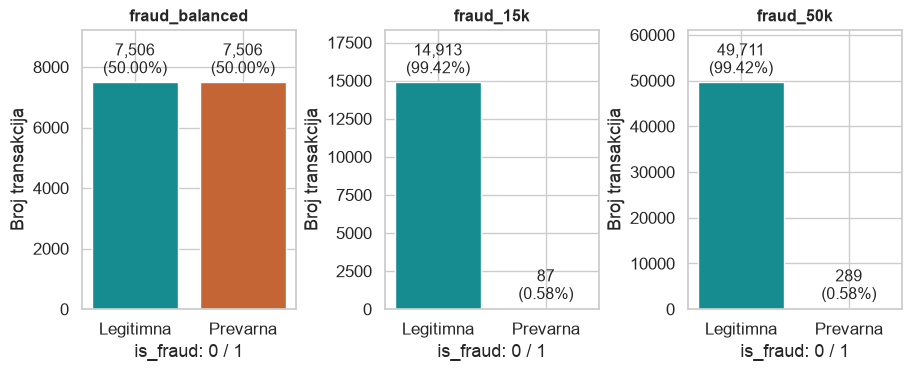

In [13]:
class_rows = []
for name, data in sources.items():
    counts = data['is_fraud'].value_counts().reindex([0, 1], fill_value=0)
    class_rows.append({'skup': name, 'ukupno': len(data), 'legitimne': int(counts[0]),
                       'prevare': int(counts[1]), 'udio_prevara_pct': 100 * counts[1] / len(data)})
class_comparison = pd.DataFrame(class_rows)
overlap_rows = []
for i, a in enumerate(sources):
    for b in list(sources)[i+1:]:
        overlap_rows.append({'skup_a': a, 'skup_b': b,
                             'zajednicke_transakcije': len(set(sources[a]['trans_num']) & set(sources[b]['trans_num']))})
overlap = pd.DataFrame(overlap_rows)
display(class_comparison.rename(columns={
    'skup': 'Skup', 'ukupno': 'Ukupno', 'legitimne': 'Legitimne',
    'prevare': 'Prevare', 'udio_prevara_pct': 'Udio prevara (%)'
}).round(2))
fig, axes = plt.subplots(1, 3, figsize=(9, 3.6), constrained_layout=True)
for ax, (name, data) in zip(axes, sources.items()):
    values = data['is_fraud'].value_counts().reindex([0, 1], fill_value=0)
    bars = ax.bar(['Legitimna', 'Prevarna'], values, color=[COLORS[0], COLORS[1]])
    ax.bar_label(bars, labels=[f'{n:,}\n({n/len(data):.2%})' for n in values], padding=3, fontsize=11.5)
    ax.set_ylim(0, max(values) * 1.23)
    ax.set_title(name.replace('.csv', ''), fontsize=11.5)
    ax.set_ylabel('Broj transakcija')
    ax.set_xlabel('is_fraud: 0 / 1')
show_plot(fig, 'raspodjela_klasa.png')

**Zaključak:** u glavnom skupu ima 7.506 legitimnih transakcija i 7.506 prevara. Odnos 50/50 nastao je namjernim odabirom podataka. U druga dva skupa prevare čine samo oko 0,58% transakcija.

Zato, kada kasnije izračunamo procenat prevara kod nekog trgovca ili vrste kupovine, taj procenat opisuje naš odabrani skup. Ne možemo ga neposredno proglasiti vjerovatnoćom prevare u stvarnom poslovanju.

### 4. Šta nam govore datum i vrijeme?

Iz datuma transakcije čitamo sat, dan u sedmici i mjesec. Iz datuma rođenja i datuma transakcije računamo približnu starost korisnika tada. Iz dvije lokacije računamo udaljenost zračnom linijom, a ne dužinu stvarnog puta kupovine.

Kolona **unix_time** predstavlja zapis vremena kao broj sekundi. Provjeravamo da li se taj zapis slaže s datumom koji možemo direktno pročitati iz kolone trans_date_trans_time.

In [14]:
eda['hour'] = eda['trans_datetime'].dt.hour
eda['day_of_week'] = eda['trans_datetime'].dt.day_of_week
eda['month'] = eda['trans_datetime'].dt.month
eda['age_years'] = (eda['trans_datetime'] - eda['birth_datetime']).dt.total_seconds() / (86400 * 365.2425)
lat1, lon1, lat2, lon2 = [np.radians(eda[c].to_numpy()) for c in ['lat', 'long', 'merch_lat', 'merch_long']]
a = np.sin((lat2-lat1)/2)**2 + np.cos(lat1)*np.cos(lat2)*np.sin((lon2-lon1)/2)**2
eda['distance_km'] = 6371.0088 * 2 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
eda['unix_offset_days'] = (eda['trans_datetime'] - eda['unix_datetime']).dt.total_seconds() / 86400

date_summary = {
    c: {'min': str(eda[c].min()), 'max': str(eda[c].max()), 'unique': int(eda[c].nunique())}
    for c in ['trans_datetime', 'birth_datetime', 'unix_datetime']
}
offsets = eda['unix_offset_days'].value_counts().sort_index()
date_summary['unix_offset_days_counts'] = {str(int(k)): int(v) for k, v in offsets.items()}
date_summary['seven_calendar_years_match'] = int((eda['unix_datetime'] + pd.DateOffset(years=7)).eq(eda['trans_datetime']).sum())
derived = ['age_years', 'hour', 'day_of_week', 'month', 'distance_km']
derived_stats = eda[derived].describe().T
temporal_tables = {}
for c in ['hour', 'day_of_week', 'month']:
    tab = eda.groupby(c)['is_fraud'].agg(broj='size', prevare='sum', udio_prevara='mean')
    temporal_tables[c] = tab
monthly = eda.groupby([eda['trans_datetime'].dt.to_period('M'), 'is_fraud']).size().unstack(fill_value=0)

date_view = pd.DataFrame({
    'Datum transakcije': date_summary['trans_datetime'],
    'Datum rođenja': date_summary['birth_datetime'],
    'Datum dobijen iz unix_time': date_summary['unix_datetime']
}).T.rename(columns={'min': 'Najranije', 'max': 'Najkasnije', 'unique': 'Različitih vremena/datuma'})
display(date_view)

# Starost je u godinama, a udaljenost zračnom linijom u kilometrima.
display(derived_stats.loc[['age_years', 'distance_km']].rename(index={
    'age_years': 'Starost (godine)', 'distance_km': 'Udaljenost (km)'
}, columns={
    'count': 'Broj', 'mean': 'Prosjek', 'std': 'Std. dev.', 'min': 'Minimum',
    '25%': 'Q1', '50%': 'Medijan', '75%': 'Q3', 'max': 'Maksimum'
}).round(2))
display(eda.groupby('is_fraud')[['age_years', 'distance_km']].agg(['mean', 'median', 'std']).rename(
    index=CLASS, columns={
        'age_years': 'Starost (godine)', 'distance_km': 'Udaljenost (km)',
        'mean': 'Prosjek', 'median': 'Medijan', 'std': 'Std. dev.'
    }).round(2))

# Godišnji periodi nisu jednako dugi; ovo su brojevi transakcija, ne rizik prevare.
year_counts = eda['trans_datetime'].dt.year.value_counts().sort_index()
year_counts.index.name = 'Godina'
display(year_counts.rename('Broj transakcija').to_frame())
display(Markdown(
    f'**Provjera zapisa vremena:** Unix datum + 7 kalendarskih godina '
    f'odgovara datumu transakcije u **{date_summary["seven_calendar_years_match"]} '
    f'od {len(eda)} redova**.'
))

,Najranije,Najkasnije,Različitih vremena/datuma
Datum transakcije,2019-01-01 07:11:55,2020-06-21 11:11:31,15006
Datum rođenja,1924-10-30 00:00:00,2005-01-29 00:00:00,962
Datum dobijen iz unix_time,2012-01-01 07:11:55,2013-06-21 11:11:31,15006


,Broj,Prosjek,Std. dev.,Minimum,Q1,Medijan,Q3,Maksimum
Starost (godine),15012.00,47.57,18.06,13.99,33.05,46.05,59.16,95.48
Udaljenost (km),15012.00,76.38,28.85,0.74,55.72,78.39,98.75,144.52


Starost (godine)                   Udaljenost (km)                  
                       Prosjek Medijan Std. dev.         Prosjek Medijan Std. dev.
is_fraud                                                                          
Legitimna (0)            46.34   44.45     17.12           76.49   78.81     28.94
Prevarna (1)             48.80   47.81     18.87           76.27   77.93     28.75

,Broj transakcija
Godina,
2019,10562
2020,4450


**Provjera zapisa vremena:** Unix datum + 7 kalendarskih godina odgovara datumu transakcije u **15012 od 15012 redova**.

**Kako čitati naredna četiri grafikona?** Gore lijevo je broj transakcija kroz mjesece. Gore desno su godine rođenja: visina stuba je broj transakcija čiji vlasnik kartice pripada toj grupi godina. Dolje lijevo je vrijeme dobijeno iz unix_time, a dolje desno približna starost korisnika.

Korisnik s više kupovina pojavljuje se više puta. Zato ovi grafikoni opisuju transakcije i njihove vlasnike, a ne popis različitih osoba.

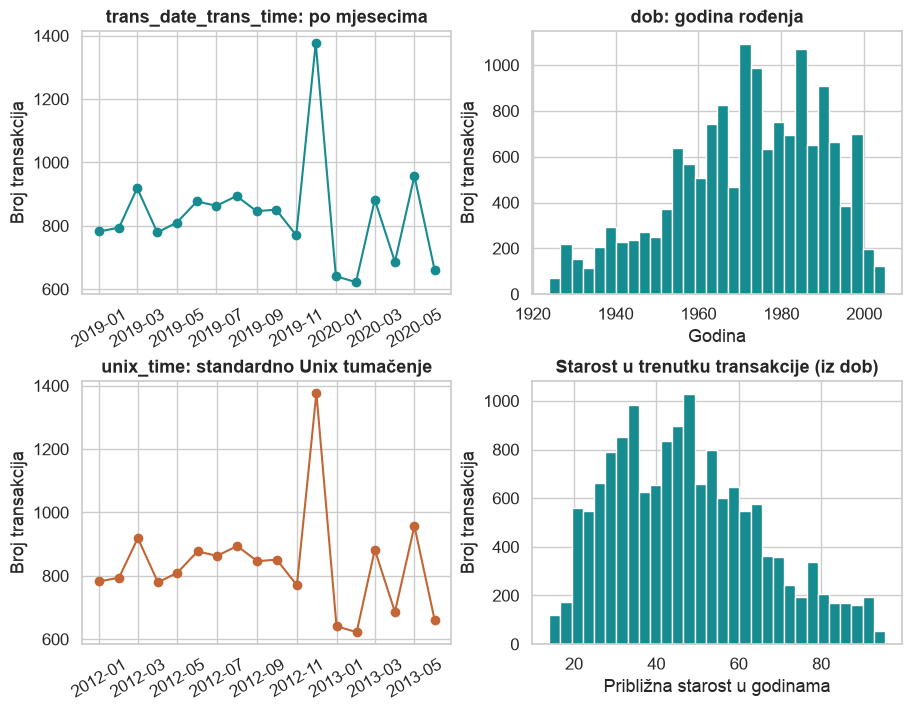

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7), constrained_layout=True)
month_counts = eda['trans_datetime'].dt.to_period('M').value_counts().sort_index()
axes[0, 0].plot(month_counts.index.to_timestamp(), month_counts, marker='o', color='#168B90')
axes[0, 0].set(title='trans_date_trans_time: po mjesecima', ylabel='Broj transakcija')
axes[0, 0].tick_params(axis='x', rotation=30)
axes[0, 1].hist(eda['birth_datetime'].dt.year, bins=30, color='#168B90', edgecolor='white')
axes[0, 1].set(title='dob: godina rođenja', xlabel='Godina', ylabel='Broj transakcija')
unix_month = eda['unix_datetime'].dt.to_period('M').value_counts().sort_index()
axes[1, 0].plot(unix_month.index.to_timestamp(), unix_month, marker='o', color='#C46535')
axes[1, 0].set(title='unix_time: standardno Unix tumačenje', ylabel='Broj transakcija')
axes[1, 0].tick_params(axis='x', rotation=30)
axes[1, 1].hist(eda['age_years'], bins=30, color='#168B90', edgecolor='white')
axes[1, 1].set(title='Starost u trenutku transakcije (iz dob)', xlabel='Približna starost u godinama', ylabel='Broj transakcija')
show_plot(fig, 'datumi.png')

**Zaključak:** tekstualni datumi transakcija obuhvataju 2019. i dio 2020. godine, a standardno čitanje unix_time daje 2012. i dio 2013. godine. Dodavanje sedam kalendarskih godina usklađuje svaki red. Uzrok razlike se ne može utvrditi iz ovih fajlova, pa za sat i starost koristimo čitljivi datum transakcije.

Starost u trenutku kupovine je približno 14–95 godina. Nije pronađen datum rođenja poslije datuma kupovine. Juni 2020. nije potpun mjesec, pa njegov manji broj redova ne treba tumačiti kao manji rizik prevare.

### 5. Koje su numeričke vrijednosti uobičajene?

Računamo statistiku iznosa, koordinata i broja stanovnika. Vrijednosti prikazujemo na dvije decimale, bez naučnog zapisa. Kolonu unix_time izostavljamo iz ove tabele jer je provjerena u dijelu o datumima. Broj kartice i poštanski broj su oznake, pa ih ne uključujemo u računanje prosjeka.

| Mjera | Kako je čitamo? |
|---|---|
| Prosjek | Zbir vrijednosti podijeljen brojem transakcija. Velike vrijednosti mogu ga podići. |
| Medijan | Sredina poredanih vrijednosti: približno polovina podataka je ispod, a polovina iznad nje. |
| Standardna devijacija | Koliko su vrijednosti rasute oko prosjeka, u istoj jedinici kao podatak. |
| Minimum i maksimum | Najmanja i najveća zabilježena vrijednost. |
| Q1 i Q3 | Granice ispod kojih je 25% i 75% vrijednosti. Između njih je srednjih 50% podataka. |

IQR je razlika Q3 − Q1. Vrijednosti dosta ispod Q1 ili iznad Q3 možemo označiti kao izdvojene. To je statistička oznaka za pregled, a ne dokaz da je vrijednost pogrešna.

In [16]:
numeric_stats = raw[continuous].describe().T
numeric_stats['skew'] = raw[continuous].skew()
for c in continuous:
    q1, q3 = raw[c].quantile([.25, .75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    numeric_stats.loc[c, 'iqr_low'] = low
    numeric_stats.loc[c, 'iqr_high'] = high
    numeric_stats.loc[c, 'outlier_count'] = int(((raw[c] < low) | (raw[c] > high)).sum())
numeric_stats.index.name = 'atribut'
class_stats = raw.groupby('is_fraud')[continuous].agg(['count', 'mean', 'std', 'median', 'min', 'max'])

# Unix zapis vremena provjeravamo u dijelu o datumima, a ovdje ga izostavljamo.
numeric_view = numeric_stats.drop(index='unix_time')[['mean', 'std', 'min', '25%', '50%', '75%', 'max']].rename(columns={
    'mean': 'Prosjek', 'std': 'Std. dev.', 'min': 'Minimum',
    '25%': 'Q1', '50%': 'Medijan', '75%': 'Q3', 'max': 'Maksimum'
})
display(numeric_view.round(2))

# IQR izdvajanje je opis raspodjele, a ne automatski razlog za brisanje.
numeric_diagnostics = numeric_stats.drop(index='unix_time')[
    ['skew', 'iqr_low', 'iqr_high', 'outlier_count']
].rename(columns={
    'skew': 'Asimetrija', 'iqr_low': 'Donja IQR granica',
    'iqr_high': 'Gornja IQR granica', 'outlier_count': 'Izdvojene transakcije'
})
numeric_diagnostics['Izdvojene transakcije'] = numeric_diagnostics['Izdvojene transakcije'].astype(int)
display(numeric_diagnostics.round(2))

,Prosjek,Std. dev.,Minimum,Q1,Medijan,Q3,Maksimum
atribut,,,,,,,
amt,299.52,373.92,1.00,20.50,89.54,477.10,6337.25
lat,38.62,5.13,20.03,34.78,39.41,42.02,66.69
long,-90.28,14.08,-165.67,-96.98,-87.41,-80.13,-67.95
city_pop,90510.75,303554.43,23.00,743.00,2526.00,21125.00,2906700.00
merch_lat,38.61,5.17,19.04,34.90,39.40,41.99,67.51
merch_long,-90.28,14.11,-166.55,-96.99,-87.36,-80.17,-67.03


,Asimetrija,Donja IQR granica,Gornja IQR granica,Izdvojene transakcije
atribut,,,,
amt,1.48,-664.41,1162.01,118
lat,0.03,23.92,52.87,66
long,-1.20,-122.27,-54.85,491
city_pop,5.62,-29830.00,51698.00,2774
merch_lat,0.03,24.26,52.63,79
merch_long,-1.19,-122.22,-54.94,480


**Primjer: iznos kupovine.** Prosjek je oko 299,52 USD, a medijan oko 89,54 USD. To znači da polovina transakcija ima iznos do približno 89,54 USD, iako je prosjek mnogo veći. Veliki iznosi podižu prosjek.

Slično je s brojem stanovnika grada: medijan je 2.526, a prosjek oko 90.511. Nekoliko velikih gradova podiže prosjek. Ne treba zaključiti da većina transakcija dolazi iz gradova sa 90 hiljada stanovnika.

**Kako čitati histograme ispod?** Vodoravna osa pokazuje vrijednost ili raspon vrijednosti, a visina stuba koliko transakcija pripada tom rasponu.

Za iznos i broj stanovnika koristimo **logaritamsku osu** da se vide i male i velike vrijednosti. Oznake su stvarni USD i broj stanovnika; jednak razmak predstavlja prelazak, na primjer, sa 1 na 10, zatim sa 10 na 100. Ostale ose koriste običan razmak.

Unix vrijeme izostavljamo jer je njegov odnos s datumom transakcije već provjeren u dijelu o datumima.

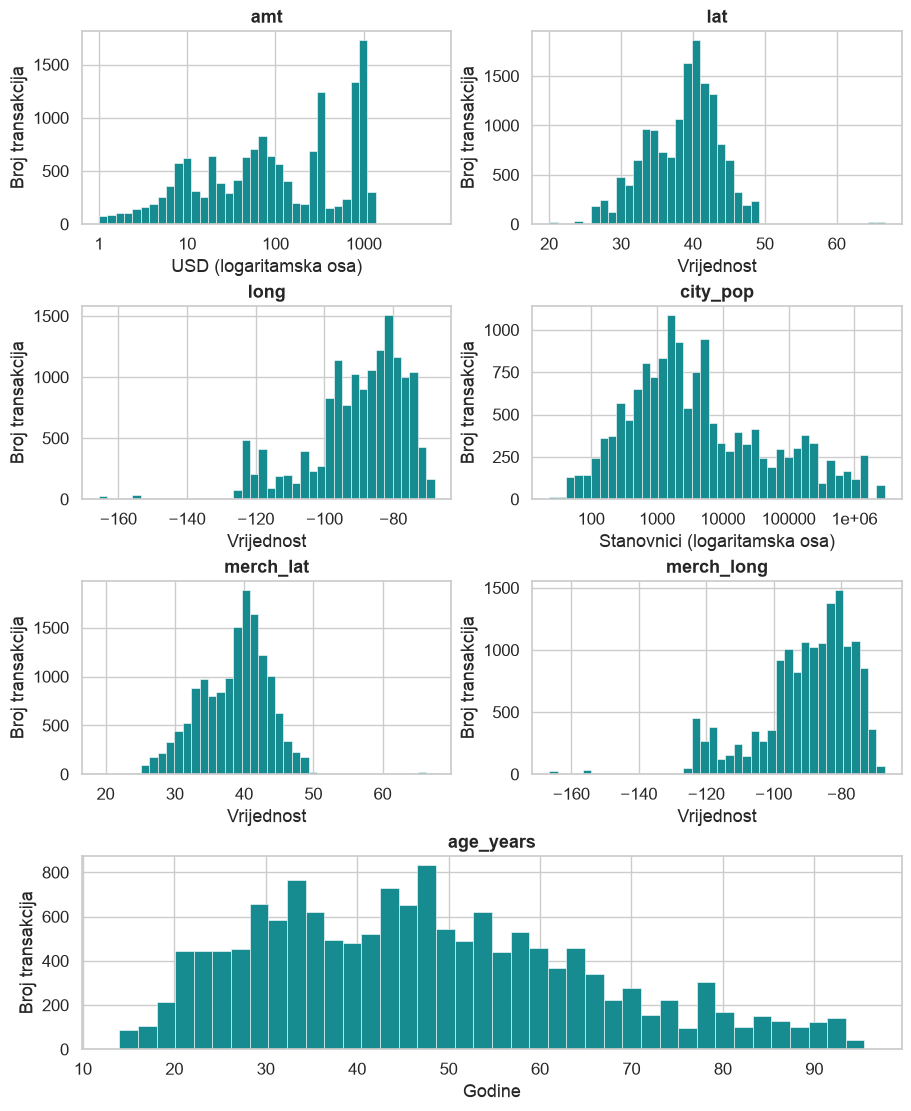

In [17]:
from matplotlib.ticker import FuncFormatter
# Unix vrijeme je već provjereno u dijelu o datumima.
histogram_columns = [c for c in continuous if c != 'unix_time'] + ['age_years']
fig = plt.figure(figsize=(9, 11), constrained_layout=True)
grid = fig.add_gridspec(4, 2)
axes = [fig.add_subplot(grid[i // 2, i % 2]) for i in range(6)]
axes.append(fig.add_subplot(grid[3, :]))
for ax, col in zip(axes, histogram_columns):
    values = eda[col].dropna()
    if col in ['amt', 'city_pop']:
        bins = np.geomspace(values.min(), values.max(), 41)
        ax.hist(values, bins=bins, color='#168B90', edgecolor='white', linewidth=.4)
        ax.set_xscale('log')
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, position: f'{value:g}'))
        ax.set_xlabel('USD (logaritamska osa)' if col == 'amt' else 'Stanovnici (logaritamska osa)')
    else:
        ax.hist(values, bins=40, color='#168B90', edgecolor='white', linewidth=.4)
        ax.set_xlabel('Godine' if col == 'age_years' else 'Vrijednost')
    ax.set_title(col)
    ax.set_ylabel('Broj transakcija')
show_plot(fig, 'numericke_distribucije.png')

**Šta je važno u ovim raspodjelama?** Iznosi i populacija imaju mnogo malih vrijednosti i manji broj velikih. Za iznos IQR pravilo označava 118 transakcija, a za populaciju 2.774 reda. Ovdje ih ne brišemo: skupa kupovina ili veliki grad mogu biti potpuno ispravni podaci.

Koordinate pokazuju geografski raspored. Negativna geografska dužina je očekivana za zapadnu hemisferu i sama po sebi nije greška.

### 6. Razlikuje li se iznos kod prevara?

Sada istu kolonu **amt** posmatramo odvojeno za dvije klase. Važno je porediti njihove raspodjele, a ne samo ukupan prosjek.

In [18]:
amount_by_class = raw.groupby('is_fraud')['amt'].agg(['count', 'mean', 'std', 'median', 'min', 'max'])
display(amount_by_class.rename(index=CLASS, columns={
    'count': 'Broj', 'mean': 'Prosjek USD', 'std': 'Std. dev. USD',
    'median': 'Medijan USD', 'min': 'Minimum USD', 'max': 'Maksimum USD'
}).round(2))

,Broj,Prosjek USD,Std. dev. USD,Medijan USD,Minimum USD,Maksimum USD
is_fraud,,,,,,
Legitimna (0),7506,67.72,140.10,47.92,1.00,6337.25
Prevarna (1),7506,531.32,390.56,396.50,1.06,1376.04


**Kako čitati dva grafikona?** Lijevi prikazuje koliki udio transakcija ima iznos manji ili jednak vrijednosti na vodoravnoj osi. Na visini 0,5 čitamo medijan, odnosno sredinu poredanih iznosa.

Desni je kutijasti dijagram: crta unutar kutije označava medijan, a kutija srednjih 50% vrijednosti. Tačke izvan krajeva označavaju vrijednosti koje se po tom pravilu izdvajaju. Granice izdvajanja na ovom dijagramu računaju se posebno za svaku klasu. Zato broj nacrtanih tačaka ne mora biti jednak ranije navedenih 118 izdvojenih iznosa iz cijelog skupa. Iznosi su na logaritamskoj osi.

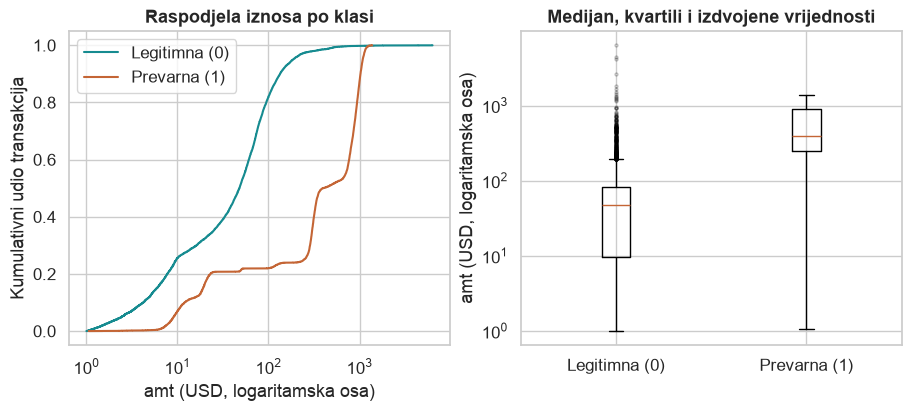

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for label, group in eda.groupby('is_fraud'):
    values = np.sort(group['amt'].to_numpy())
    axes[0].step(values, np.arange(1, len(values)+1)/len(values), where='post',
                 label=CLASS[label], color=COLORS[label])
axes[0].set_xscale('log')
axes[0].set(xlabel='amt (USD, logaritamska osa)', ylabel='Kumulativni udio transakcija', title='Raspodjela iznosa po klasi')
axes[0].legend()
axes[1].boxplot([eda.loc[eda.is_fraud.eq(label), 'amt'] for label in [0, 1]],
                tick_labels=[CLASS[0], CLASS[1]], showfliers=True,
                flierprops={'markersize': 2, 'alpha': .25})
axes[1].set_yscale('log')
axes[1].set(ylabel='amt (USD, logaritamska osa)', title='Medijan, kvartili i izdvojene vrijednosti')
show_plot(fig, 'iznos_po_klasi.png')

**Zaključak:** medijan legitimnih transakcija je 47,92 USD, a prevara 396,50 USD. Prevare u ovom skupu češće imaju veće iznose.

Ipak, raspodjele se preklapaju. Najveća kupovina od 6.337,25 USD označena je kao legitimna. Zato pravilo „velik iznos znači prevaru“ ne bi bilo tačno za sve redove.

### 7. Šta saznajemo iz kategorija i oznaka?

Kategoričke kolone sadrže nazive ili oznake: trgovca, vrstu kupovine, grad, zanimanje, spol i slično. Za njih brojimo pojavljivanja.

**Frekvencija** je broj transakcija s određenom vrijednošću. Ako se trgovac pojavljuje 72 puta, to znači 72 transakcije kod tog trgovca. To nije 72 različita trgovca.

Za svaki atribut računamo potpune frekvencije u varijabli category_tables. Tabela ispod daje pregled svih kategoričkih kolona, a grafikoni radi preglednosti prikazuju najčešćih osam vrijednosti.

In [20]:
category_tables = {}
category_summary = []
for c in categorical:
    counts = raw.groupby(c, dropna=False)['is_fraud'].agg(broj='size', prevare='sum', udio_prevara='mean')
    counts['udio_pct'] = 100 * counts['broj'] / len(raw)
    counts = counts.sort_values('broj', ascending=False)
    counts.index.name = c
    category_tables[c] = counts
    top = counts.iloc[0]
    category_summary.append({'atribut': c, 'broj_kategorija': len(counts),
                             'najcesca_vrijednost': str(counts.index[0]),
                             'najcesca_broj': int(top['broj']), 'najcesca_pct': float(top['udio_pct']),
                             'jednokratne_kategorije': int(counts['broj'].eq(1).sum())})
category_summary = pd.DataFrame(category_summary)

display(category_summary.rename(columns={
    'atribut': 'Kolona', 'broj_kategorija': 'Različitih vrijednosti',
    'najcesca_vrijednost': 'Najčešća vrijednost', 'najcesca_broj': 'Broj transakcija',
    'najcesca_pct': 'Udio u skupu (%)', 'jednokratne_kategorije': 'Vrijednosti sa samo 1 transakcijom'
}).round(2))

,Kolona,Različitih vrijednosti,Najčešća vrijednost,Broj transakcija,Udio u skupu (%),Vrijednosti sa samo 1 transakcijom
0,cc_num,977,630451534402,38,0.25,10
1,merchant,693,fraud_Kilback LLC,72,0.48,0
2,category,14,grocery_pos,2494,16.61,0
3,first,352,Christopher,330,2.20,2
4,last,480,Smith,301,2.01,4
5,gender,2,F,7835,52.19,0
6,street,977,561 Little Plain Apt. 738,38,0.25,10
7,city,889,Warren,57,0.38,10
8,state,51,TX,1024,6.82,0
9,zip,964,82514,45,0.30,10


**Kako čitati stubove?** Duži stub znači više transakcija s nazivom prikazanim lijevo. Na primjer, uz **category** vidimo koliko transakcija pripada svakoj vrsti kupovine. Naslov navodi koliko vrijednosti je prikazano od ukupnog broja.

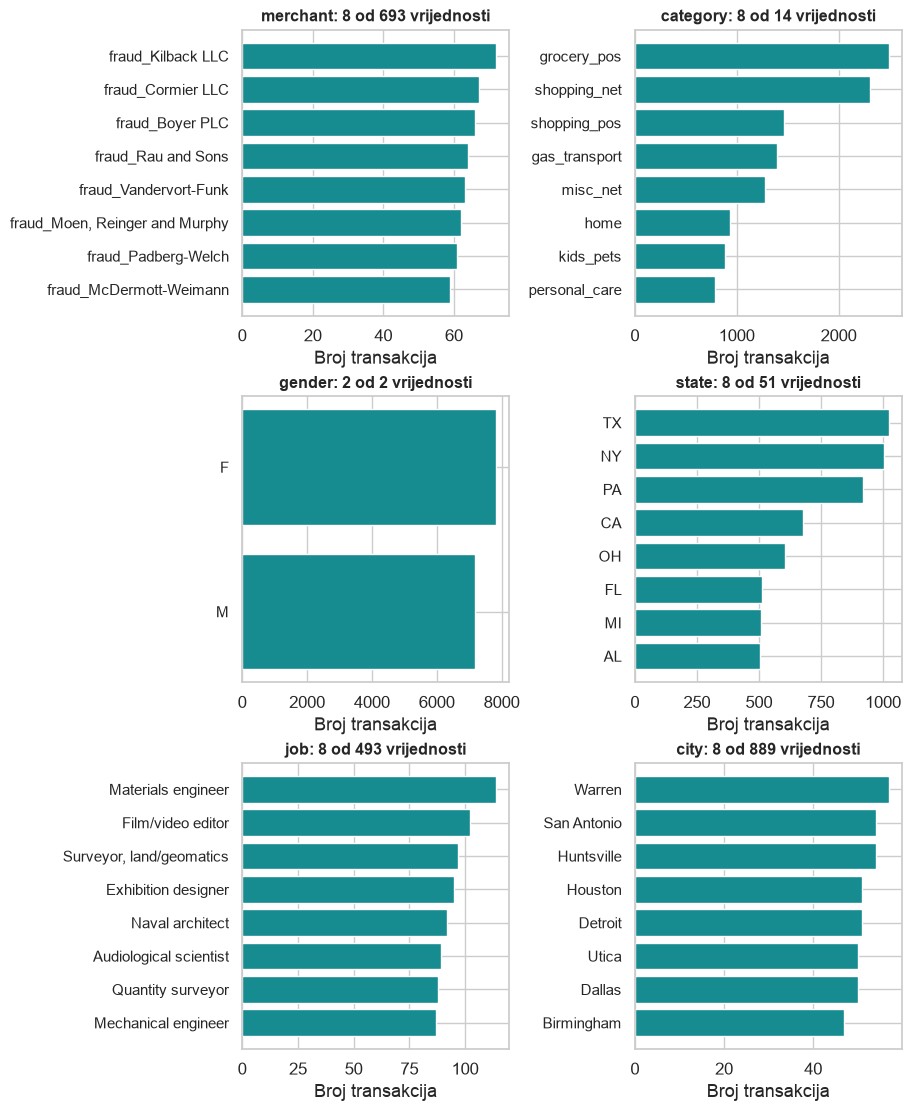

In [21]:
def top_categories(ax, c):
    values = category_tables[c]['broj'].head(8).iloc[::-1]
    labels = [str(v) if len(str(v)) <= 30 else str(v)[:27]+'…' for v in values.index]
    ax.barh(labels, values.to_numpy(), color='#168B90')
    ax.set_title(f'{c}: {len(values)} od {len(category_tables[c])} vrijednosti', fontsize=11.5)
    ax.set_xlabel('Broj transakcija')
    ax.tick_params(axis='y', labelsize=11)

fig, axes = plt.subplots(3, 2, figsize=(9, 11), constrained_layout=True)
for ax, c in zip(axes.flat, ['merchant', 'category', 'gender', 'state', 'job', 'city']):
    top_categories(ax, c)
show_plot(fig, 'kategoricke_distribucije.png')

**Zaključak:** imamo 693 trgovca i 14 vrsta kupovine. Najčešća vrsta je grocery_pos, s 2.494 transakcije. Najčešći pojedinačni trgovac ima 72 transakcije.

Svi nazivi trgovaca počinju sa fraud_. Pošto je taj dio naziva isti kod obje klase, ne možemo iz njega zaključiti da je transakcija prevara.

**Kako čitati oznake kartica i transakcija?** Za cc_num i street vodoravna osa pokazuje koliko se puta jedna oznaka ponovila, a visina stuba koliko oznaka pripada tom rasponu broja ponavljanja.

Kod trans_num postoji samo stub na broju 1: svih 15.012 oznaka pojavljuje se tačno jednom. Kod imena, prezimena i poštanskih brojeva prikazujemo najčešće vrijednosti.

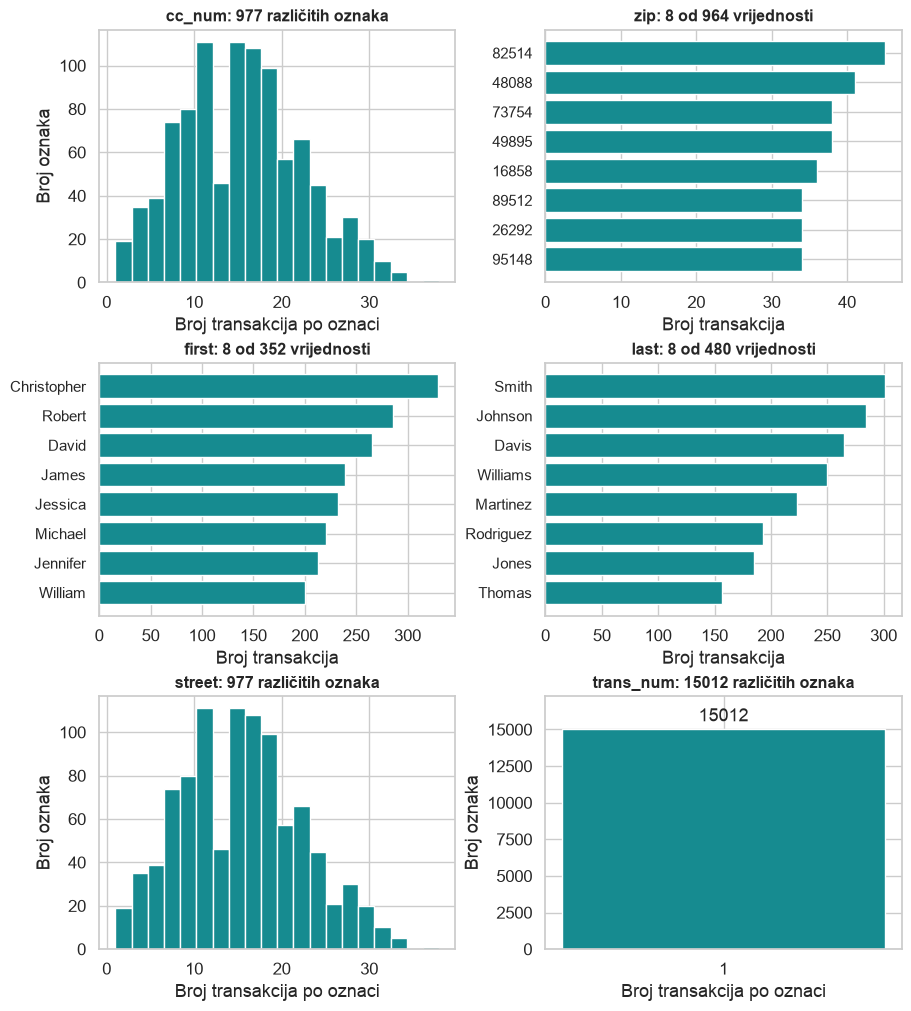

In [22]:
fig, axes = plt.subplots(3, 2, figsize=(9, 10), constrained_layout=True)
for ax, c in zip(axes.flat, ['cc_num', 'zip', 'first', 'last', 'street', 'trans_num']):
    if c in ['cc_num', 'street', 'trans_num']:
        frequencies = category_tables[c]['broj']
        if frequencies.nunique() == 1:
            bars = ax.bar([int(frequencies.iloc[0])], [len(frequencies)], width=.5, color='#168B90')
            ax.bar_label(bars, padding=3)
            ax.set_xticks([int(frequencies.iloc[0])])
            ax.set_ylim(0, len(frequencies)*1.15)
        else:
            ax.hist(frequencies, bins=20, color='#168B90', edgecolor='white')
        ax.set_title(f'{c}: {len(frequencies)} različitih oznaka', fontsize=11.5)
        ax.set_xlabel('Broj transakcija po oznaci')
        ax.set_ylabel('Broj oznaka')
    else:
        top_categories(ax, c)
show_plot(fig, 'identifikatori.png')

**Zaključak:** ista kartica ili adresa pripada većem broju transakcija. Imena i prezimena također se ponavljaju, ali nisu jedinstvene oznake osoba.

Ove kolone mogu pomoći provjeri identiteta i ponavljanja. Kasnije treba paziti da model ne nauči napamet određene korisnike umjesto obrazaca ponašanja koji važe i za nove korisnike.

### 8. Kako su vrste kupovine zastupljene u dvije klase?

Grafikon poredi **raspodjelu vrsta kupovine među legitimnim transakcijama i među prevarama**. Svaka klasa ima svoj zbir od 100%.

- **Tirkizno:** od svih legitimnih transakcija, koliki dio pripada ovoj kategoriji?
- **Narandžasto:** od svih prevara, koliki dio pripada ovoj kategoriji?

**Primjer:** narandžasti stub od 20% znači da 20 od 100 prevara pripada toj vrsti kupovine. To nije procenat prevara među svim kupovinama te vrste.

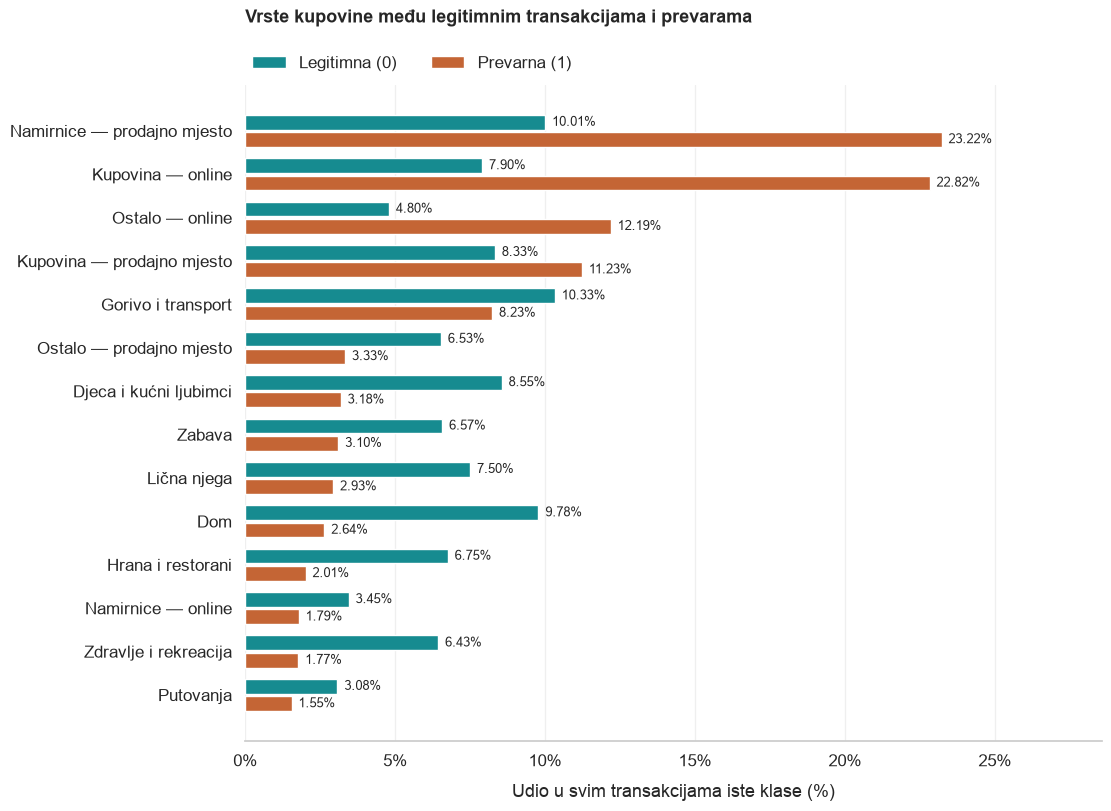

In [23]:
from matplotlib.ticker import PercentFormatter

# Nazive prevodimo samo za prikaz; originalni podaci ostaju isti.
category_labels = {
    'grocery_pos': 'Namirnice — prodajno mjesto',
    'grocery_net': 'Namirnice — online',
    'shopping_pos': 'Kupovina — prodajno mjesto',
    'shopping_net': 'Kupovina — online',
    'misc_pos': 'Ostalo — prodajno mjesto',
    'misc_net': 'Ostalo — online',
    'gas_transport': 'Gorivo i transport',
    'kids_pets': 'Djeca i kućni ljubimci',
    'entertainment': 'Zabava',
    'personal_care': 'Lična njega',
    'home': 'Dom',
    'food_dining': 'Hrana i restorani',
    'health_fitness': 'Zdravlje i rekreacija',
    'travel': 'Putovanja',
}

# Svaku klasu zasebno posmatramo kao 100%.
category_mix = pd.crosstab(
    eda['category'], eda['is_fraud'], normalize='columns'
).mul(100).sort_values(1, ascending=False)

fig, ax = plt.subplots(figsize=(11, 8), constrained_layout=True)
y = np.arange(len(category_mix))
for label, offset in [(0, -.2), (1, .2)]:
    bars = ax.barh(
        y + offset, category_mix[label], height=.34,
        label=CLASS[label], color=COLORS[label]
    )
    ax.bar_label(bars, labels=[f'{value:.2f}%' for value in category_mix[label]],
                 padding=5, fontsize=9)

ax.set_yticks(y, [category_labels.get(c, c) for c in category_mix.index])
ax.invert_yaxis()
ax.set_xlim(0, category_mix.to_numpy().max() * 1.23)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.set_xlabel('Udio u svim transakcijama iste klase (%)', labelpad=10)
ax.set_title('Vrste kupovine među legitimnim transakcijama i prevarama',
             loc='left', pad=45, fontsize=13)
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.01), ncol=2,
          frameon=False, borderaxespad=0)
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=.3)
ax.grid(axis='y', visible=False)
sns.despine(ax=ax, left=True)
show_plot(fig, 'kategorije_po_klasi.png')

**Drugo pitanje: koliki dio transakcija unutar jedne kategorije čine prevare?**

Tabela ispod polazi od svih transakcija jedne kategorije, pa ih dijeli na legitimne i prevarne.

**Udio prevara u kategoriji = broj prevara u kategoriji ÷ ukupan broj transakcija u kategoriji × 100.**

Ako kategorija ima 100 transakcija, od kojih je 60 prevara, njen udio u tabeli je 60%. Na grafikonu iznad nazivnik je drugačiji: ukupan broj transakcija odgovarajuće klase.

In [24]:
category_frequencies = category_tables['category'][['broj', 'prevare']].copy()
category_frequencies['legitimne'] = category_frequencies['broj'] - category_frequencies['prevare']
category_frequencies['udio_prevara_pct'] = (
    100 * category_frequencies['prevare'] / category_frequencies['broj']
)
category_frequencies = category_frequencies.sort_values('udio_prevara_pct', ascending=False)
category_view = category_frequencies.rename(index=category_labels).rename(columns={
    'broj': 'Ukupno transakcija',
    'legitimne': 'Legitimne',
    'prevare': 'Prevare',
    'udio_prevara_pct': 'Prevare u kategoriji (%)'
})[['Ukupno transakcija', 'Legitimne', 'Prevare', 'Prevare u kategoriji (%)']]
category_view.index.name = 'Vrsta kupovine'
display(category_view.style.format({
    'Ukupno transakcija': '{:,.0f}', 'Legitimne': '{:,.0f}',
    'Prevare': '{:,.0f}', 'Prevare u kategoriji (%)': '{:.2f}%'
}, thousands=' '))

,Ukupno transakcija,Legitimne,Prevare,Prevare u kategoriji (%)
Vrsta kupovine,,,,
Kupovina — online,2 306,593,1 713,74.28%
Ostalo — online,1 275,360,915,71.76%
Namirnice — prodajno mjesto,2 494,751,1 743,69.89%
Kupovina — prodajno mjesto,1 468,625,843,57.43%
Gorivo i transport,1 393,775,618,44.36%
Namirnice — online,393,259,134,34.10%
Ostalo — prodajno mjesto,740,490,250,33.78%
Putovanja,347,231,116,33.43%
Zabava,726,493,233,32.09%


**Šta uočavamo?** Kupovina namirnica na prodajnom mjestu i online kupovina najzastupljenije su kategorije među prevarama. Kod drugih kategorija, poput doma i zdravlja i rekreacije, udio među legitimnim transakcijama veći je nego među prevarama. Vrsta kupovine zato može biti koristan atribut modela.

**Grafikon i tabela odgovaraju na različita pitanja:** grafikon pokazuje gdje su raspoređene transakcije svake klase; tabela pokazuje sastav pojedinačne kategorije.

Svi procenti opisuju naš **balansirani uzorak**. Udio prevara iz tabele nije procjena stvarnog rizika prevare u poslovanju.

### 9. U koje vrijeme se češće pojavljuju prevare?

Za svaki sat i dan brojimo transakcije posebno po klasi. I ovdje se svaka klasa zasebno sabira na 100%, kako bismo mogli porediti vrijeme pojavljivanja.

Vodoravna osa prikazuje sat ili dan, a uspravna procenat transakcija **unutar jedne klase**. Nula na osi sata znači ponoć.

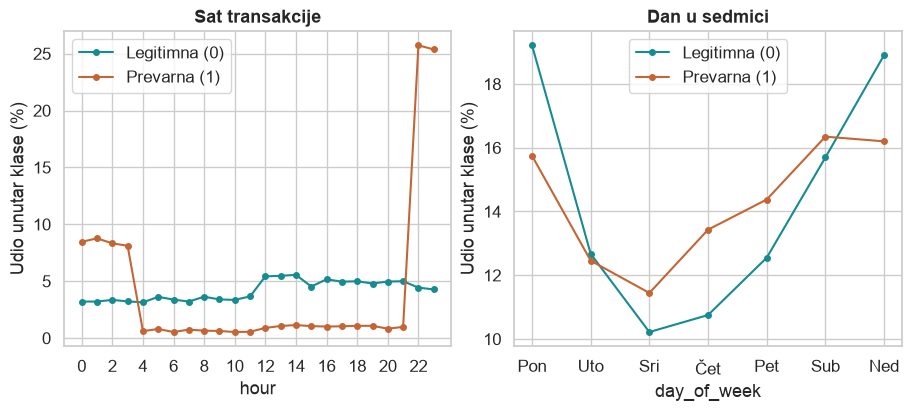

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, c, title in zip(axes, ['hour', 'day_of_week'], ['Sat transakcije', 'Dan u sedmici']):
    normalized = pd.crosstab(eda[c], eda['is_fraud'], normalize='columns') * 100
    for label in [0, 1]:
        ax.plot(normalized.index, normalized[label], marker='o', markersize=4, label=CLASS[label], color=COLORS[label])
    ax.set(title=title, ylabel='Udio unutar klase (%)', xlabel=c)
    if c == 'hour':
        ax.set_xticks(range(0, 24, 2))
    else:
        ax.set_xticks(range(7), ['Pon', 'Uto', 'Sri', 'Čet', 'Pet', 'Sub', 'Ned'])
    ax.legend()
show_plot(fig, 'vremenski_obrasci.png')

In [26]:
night = eda['hour'].isin([22, 23, 0, 1, 2, 3])
night_share = eda.assign(night=night).groupby('is_fraud')['night'].mean() * 100
display(night_share.rename(index=CLASS).rename('Transakcije od 22:00 do 03:59 (%)').round(2).to_frame())

,Transakcije od 22:00 do 03:59 (%)
is_fraud,
Legitimna (0),21.72
Prevarna (1),84.76


**Zaključak:** od svih prevara u našem skupu, oko 84,76% desilo se od 22:00 do 03:59. Kod legitimnih transakcija taj udio je oko 21,72%. Vrijeme zato pokazuje izraženu razliku između klasa.

Ovo ne znači da je 84,76% svih noćnih kupovina prevara. Polazimo od dvije odvojene grupe i pitamo u koliko sati se pojavljuju njihovi redovi. Razlika po danima u sedmici je manja nego razlika po satima.

### 10. Koje se numeričke kolone mijenjaju zajedno?

**Korelacija** je broj od −1 do 1:
- Blizu +1: dvije vrijednosti često rastu zajedno.
- Blizu −1: kada jedna raste, druga često opada.
- Blizu 0: nema izražene linearne veze; drugi obrasci ipak mogu postojati.

Pearsonov koeficijent opisuje linearnu vezu. Spearmanov poredi redoslijed vrijednosti i služi kao dodatna provjera. Računamo oba.

Kada jednu numeričku kolonu poredimo s ciljem 0/1, pozitivan rezultat govori da su veće vrijednosti više zastupljene u klasi 1. **Korelacija 0,62 nije 62% tačnosti modela** i ne dokazuje da promjena te vrijednosti izaziva prevaru.

In [27]:
corr_columns = continuous + ['age_years', 'hour', 'day_of_week', 'distance_km', 'is_fraud']
pearson = eda[corr_columns].corr(method='pearson')
spearman = eda[corr_columns].corr(method='spearman')
correlation_target = pd.DataFrame({'pearson': pearson['is_fraud'].drop('is_fraud'),
                                    'spearman': spearman['is_fraud'].drop('is_fraud')})

display(correlation_target.rename(columns={'pearson': 'Pearson', 'spearman': 'Spearman'}).round(2))
display(pd.DataFrame({
    'Par kolona': ['lat i merch_lat', 'long i merch_long'],
    'Pearson': [pearson.loc['lat', 'merch_lat'], pearson.loc['long', 'merch_long']]
}).round(2))

,Pearson,Spearman
amt,0.62,0.58
lat,0.01,0.00
long,0.03,0.04
city_pop,0.02,0.01
unix_time,-0.03,-0.03
merch_lat,0.01,0.00
merch_long,0.03,0.04
age_years,0.07,0.06
hour,0.09,0.16
day_of_week,0.01,0.01


,Par kolona,Pearson
0,lat i merch_lat,0.99
1,long i merch_long,1.00


**Kako čitati matricu?** Pronađemo jednu kolonu na lijevoj strani i drugu na donjoj osi. Broj na presjeku je njihova korelacija. Dijagonala je 1 jer se svaka kolona poredi sama sa sobom. Prikazana je jedna polovina matrice jer druga ponavlja iste parove.

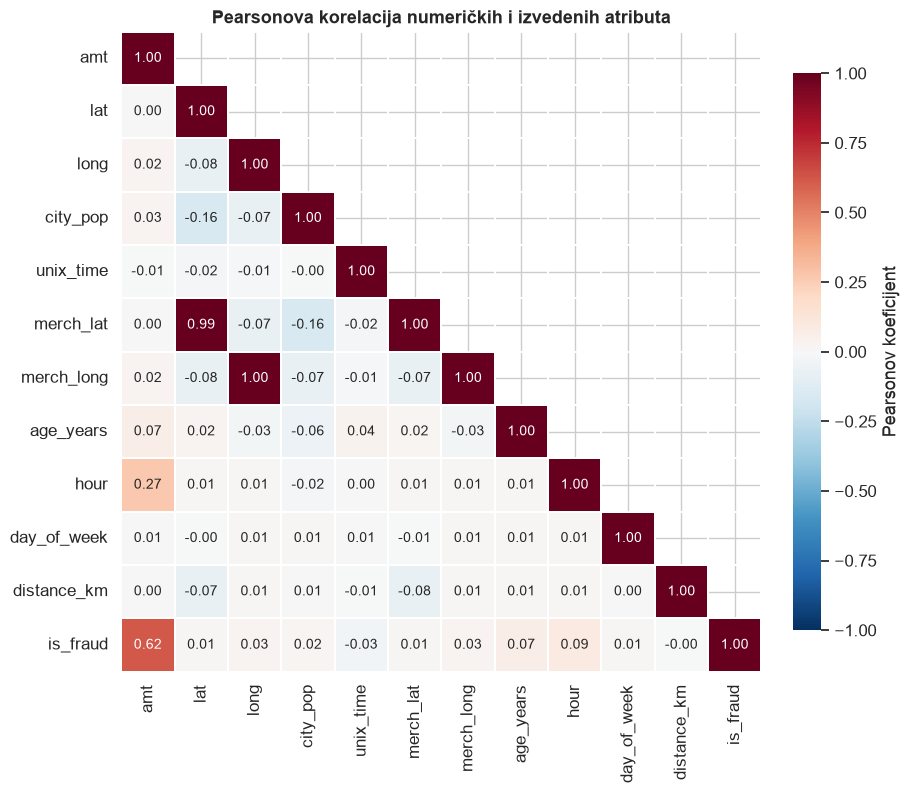

In [28]:
fig, ax = plt.subplots(figsize=(9, 8), constrained_layout=True)
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
sns.heatmap(pearson, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            vmin=-1, vmax=1, square=True, linewidths=.3, annot_kws={'size':10}, ax=ax,
            cbar_kws={'label':'Pearsonov koeficijent', 'shrink':.8})
ax.set_title('Pearsonova korelacija numeričkih i izvedenih atributa')
show_plot(fig, 'korelacije.png')

**Zaključak:** iznos ima Pearsonovu korelaciju oko 0,62 s oznakom prevare, što je u skladu s većim iznosima u klasi prevara. Spearmanova vrijednost je oko 0,58 i potvrđuje sličan obrazac u redoslijedu iznosa.

Širina korisnika i trgovca imaju međusobnu korelaciju oko 0,99, a njihove dužine oko 1,00 (zaokruženo na dvije decimale; koordinate nisu identične). Te kolone nose vrlo slične informacije o lokaciji. To ne znači da su snažno povezane s prevarom: njihova pojedinačna veza s ciljem je slaba.

Sat ima malu linearnu korelaciju s ciljem, iako se noćni obrazac jasno vidi. Razlog je što sati idu u krug: 23 i 0 su blizu u vremenu, a numerički su daleko. Zato grafikon i jedna korelacija odgovaraju na različita pitanja.

### 11. Kratak zaključak za svaku od 22 kolone

Ovo je pregled za ponavljanje. Svaka kolona ima svoj opis i nalaz; detaljne tabele i grafikoni su u odgovarajućim dijelovima iznad.

In [29]:
def cat_note(c, explanation):
    tab = category_tables[c]
    top = tab.iloc[0]
    return (f'{len(tab)} različitih vrijednosti. Najčešća: `{tab.index[0]}` '
            f'({int(top["broj"])} transakcija; {f(top["udio_pct"])}%). {explanation}')

notes = {
    'trans_date_trans_time': f'Raspon {eda.trans_datetime.min()} – {eda.trans_datetime.max()}; '
        f'{raw.trans_date_trans_time.nunique()} različitih vremena. Sat pokazuje izražen obrazac po klasi; '
        'broj transakcija po mjesecu zavisi i od dužine posmatranog intervala. Juni 2020. je nepotpun.',
    'cc_num': f'{raw.cc_num.nunique()} različitih kartica; jedna kartica se ponavlja u više redova. '
        'Identifikator se čuva kao tekst, bez srednje vrijednosti ili numeričke korelacije. '
        'Ponavljanje korisnika treba uzeti u obzir pri kasnijoj podjeli podataka.',
    'merchant': cat_note('merchant', 'Prefiks `fraud_` je zajednički svim redovima i ne označava ciljnu klasu. '
        'Za neke trgovce imamo malo transakcija, pa zaključak na osnovu tih nekoliko redova može biti nepouzdan.'),
    'category': cat_note('category', 'Grafikon pokazuje različitu zastupljenost kategorija u dvije klase. '
        'Udio prevara po kategoriji opisuje balansirani uzorak.'),
    'amt': f'Srednja vrijednost {f(raw.amt.mean())} USD, medijan {f(raw.amt.median())} USD, '
        f'standardna devijacija {f(raw.amt.std())} USD, maksimum {f(raw.amt.max())} USD. '
        f'Medijan je {f(raw.loc[raw.is_fraud.eq(0), "amt"].median())} USD za legitimne i '
        f'{f(raw.loc[raw.is_fraud.eq(1), "amt"].median())} USD za prevarne transakcije. '
        'Desni rep je dug; najveći iznos pripada legitimnoj transakciji, pa ekstrem nije automatski prevara.',
    'first': cat_note('first', 'Ime nije jedinstveno za korisnika; frekvencije su brojevi transakcija, ne broj osoba. '
        'Model bi mogao naučiti napamet imena umjesto ponašanja pri kupovini.'),
    'last': cat_note('last', 'Prezime nije jedinstveno za korisnika; tretirati kao lični identifikacioni podatak, '
        'a ne kao ordinalnu ili numeričku veličinu.'),
    'gender': cat_note('gender', 'Opisuje spol vlasnika kartice. Sama frekvencija ne pokazuje '
        'koliko je ovaj atribut koristan za razlikovanje klasa.'),
    'street': cat_note('street', 'Adrese se ponavljaju kroz više transakcija. Veliki broj različitih adresa i '
        'vezanost za identitet ograničavaju neposredno tumačenje prediktivne vrijednosti.'),
    'city': cat_note('city', 'Prikaz najčešćih osam nije potpuna raspodjela. Povezanost s klasom '
        'može odražavati ponavljanje istih korisnika i rijetke kategorije.'),
    'state': cat_note('state', 'Regionalne razlike u ovom uzorku ne predstavljaju dokaz stvarnog regionalnog rizika.'),
    'zip': cat_note('zip', f'{checks["zip_shorter_than_5"]} transakcija ima poštanski broj kraći od pet znakova. '
        'Vrijednosti su kategoričke oznake; tekstualno učitavanje čuva trenutno zapisano stanje, bez obnavljanja izostavljenih nula.'),
    'lat': f'Raspon {f(raw.lat.min(),2)} – {f(raw.lat.max(),2)}; sredina {f(raw.lat.mean(),2)}. '
        f'Pearsonova korelacija s merch_lat je {f(pearson.loc["lat", "merch_lat"],2)}, pa ove dvije kolone nose vrlo sličnu informaciju o lokaciji. Prikaz je zaokružen.',
    'long': f'Raspon {f(raw.long.min(),2)} – {f(raw.long.max(),2)}; sredina {f(raw.long.mean(),2)}. '
        f'Pearsonova korelacija s merch_long je {f(pearson.loc["long", "merch_long"],2)}. '
        'Prikazana korelacija je zaokružena, a ne dokaz identičnih koordinata. Negativan predznak koordinate nije neispravna vrijednost.',
    'city_pop': f'Medijan {f(raw.city_pop.median(),0)}, sredina {f(raw.city_pop.mean(),2)}, '
        f'maksimum {f(raw.city_pop.max(),0)} stanovnika. Vrlo asimetrična raspodjela; '
        f'{int(numeric_stats.loc["city_pop", "outlier_count"])} redova je izvan granica 1,5 × IQR, '
        'što samo po sebi nije razlog za uklanjanje velikih gradova.',
    'job': cat_note('job', 'Mnoga zanimanja su rijetka i vezana za ponovljene korisnike; '
        'procjene po malim grupama mogu biti nestabilne.'),
    'dob': f'Raspon rođenja {eda.birth_datetime.min().date()} – {eda.birth_datetime.max().date()}; '
        f'{raw.dob.nunique()} datuma. Približna starost po transakciji je '
        f'{f(eda.age_years.min(),2)} – {f(eda.age_years.max(),2)} godina; '
        'svi datumi rođenja prethode transakcijama. Korisnik s više transakcija pojavljuje se više puta na histogramu.',
    'trans_num': f'Svih {raw.trans_num.nunique()} vrijednosti je jedinstveno. '
        'Služi za identifikaciju, provjeru duplikata i preklapanja skupova; nema korisnu kontinuiranu distribuciju.',
    'unix_time': f'Standardno Unix tumačenje daje {eda.unix_datetime.min()} – {eda.unix_datetime.max()}. '
        f'Dodavanje sedam kalendarskih godina odgovara tekstualnom vremenu u svih '
        f'{date_summary["seven_calendar_years_match"]} redova. Opažena nedosljednost se ne ispravlja prećutno; '
        'vremenske obrasce izvodimo iz trans_date_trans_time.',
    'merch_lat': f'Raspon {f(raw.merch_lat.min(),2)} – {f(raw.merch_lat.max(),2)}; '
        'sve vrijednosti u dozvoljenom rasponu geografske širine. Jako prati lat; '
        'udaljenost para koordinata pruža dodatni opis njihovog odnosa.',
    'merch_long': f'Raspon {f(raw.merch_long.min(),2)} – {f(raw.merch_long.max(),2)}; '
        'sve vrijednosti u dozvoljenom rasponu geografske dužine. Jako prati long; '
        'ne treba proizvoljno tumačiti svaku geografsku izdvojenu vrijednost kao prevaru.',
    'is_fraud': 'Ciljna binarna klasa: 7.506 legitimnih i 7.506 prevarnih transakcija. '
        'Odnos 50/50 je namjerno napravljen undersamplingom; u druga dva uzorka prevare čine oko 0,58%. '
        'Cilj se ne uključuje među ulazne atribute modela.',
}
for c in original_columns:
    display(Markdown(f'**`{c}` — {semantic[c]}.** {notes[c]}'))

**`trans_date_trans_time` — datum/vrijeme.** Raspon 2019-01-01 07:11:55 – 2020-06-21 11:11:31; 15006 različitih vremena. Sat pokazuje izražen obrazac po klasi; broj transakcija po mjesecu zavisi i od dužine posmatranog intervala. Juni 2020. je nepotpun.

**`cc_num` — identifikator kartice.** 977 različitih kartica; jedna kartica se ponavlja u više redova. Identifikator se čuva kao tekst, bez srednje vrijednosti ili numeričke korelacije. Ponavljanje korisnika treba uzeti u obzir pri kasnijoj podjeli podataka.

**`merchant` — kategorički.** 693 različitih vrijednosti. Najčešća: `fraud_Kilback LLC` (72 transakcija; 0,48%). Prefiks `fraud_` je zajednički svim redovima i ne označava ciljnu klasu. Za neke trgovce imamo malo transakcija, pa zaključak na osnovu tih nekoliko redova može biti nepouzdan.

**`category` — kategorički.** 14 različitih vrijednosti. Najčešća: `grocery_pos` (2494 transakcija; 16,61%). Grafikon pokazuje različitu zastupljenost kategorija u dvije klase. Udio prevara po kategoriji opisuje balansirani uzorak.

**`amt` — numerički.** Srednja vrijednost 299,52 USD, medijan 89,54 USD, standardna devijacija 373,92 USD, maksimum 6 337,25 USD. Medijan je 47,92 USD za legitimne i 396,50 USD za prevarne transakcije. Desni rep je dug; najveći iznos pripada legitimnoj transakciji, pa ekstrem nije automatski prevara.

**`first` — kategorički.** 352 različitih vrijednosti. Najčešća: `Christopher` (330 transakcija; 2,20%). Ime nije jedinstveno za korisnika; frekvencije su brojevi transakcija, ne broj osoba. Model bi mogao naučiti napamet imena umjesto ponašanja pri kupovini.

... (12 outputs left out)

**`unix_time` — numerički (vrijeme).** Standardno Unix tumačenje daje 2012-01-01 07:11:55 – 2013-06-21 11:11:31. Dodavanje sedam kalendarskih godina odgovara tekstualnom vremenu u svih 15012 redova. Opažena nedosljednost se ne ispravlja prećutno; vremenske obrasce izvodimo iz trans_date_trans_time.

**`merch_lat` — numerički.** Raspon 19,04 – 67,51; sve vrijednosti u dozvoljenom rasponu geografske širine. Jako prati lat; udaljenost para koordinata pruža dodatni opis njihovog odnosa.

**`merch_long` — numerički.** Raspon -166,55 – -67,03; sve vrijednosti u dozvoljenom rasponu geografske dužine. Jako prati long; ne treba proizvoljno tumačiti svaku geografsku izdvojenu vrijednost kao prevaru.

**`is_fraud` — binarna ciljna klasa.** Ciljna binarna klasa: 7.506 legitimnih i 7.506 prevarnih transakcija. Odnos 50/50 je namjerno napravljen undersamplingom; u druga dva uzorka prevare čine oko 0,58%. Cilj se ne uključuje među ulazne atribute modela.

### 12. Možemo li tri CSV fajla smatrati odvojenim skupovima?

Prije kasnijeg treniranja provjeravamo pojavljuje li se ista transakcija u više datoteka. Poredimo jedinstvene oznake trans_num. Broj zajedničkih oznaka prikazan je ispod.

In [30]:
display(overlap.rename(columns={
    'skup_a': 'Prvi skup', 'skup_b': 'Drugi skup',
    'zajednicke_transakcije': 'Zajedničkih transakcija'
}))

,Prvi skup,Drugi skup,Zajedničkih transakcija
0,fraud_balanced.csv,fraud_15k.csv,7593
1,fraud_balanced.csv,fraud_50k.csv,7795
2,fraud_15k.csv,fraud_50k.csv,15000


**Zaključak:** balansirani skup dijeli 7.593 transakcije sa skupom 15k i 7.795 sa skupom 50k. Svih 15.000 transakcija manjeg skupa nalazi se i u skupu 50k.

Ako modelu pokažemo transakciju pri učenju, a zatim istu transakciju koristimo za provjeru, rezultat ne pokazuje kako radi na novim podacima. Zato prije modeliranja treba napraviti odvojene dijelove za učenje, podešavanje i završnu provjeru. Balansira se dio za učenje.

### Šta smo naučili i čemu to služi?

- **Kvalitet:** nema praznih ćelija ni dupliranih transakcija. Ipak, dva zapisa vremena se ne slažu, a neki ZIP zapisi imaju četiri cifre.
- **Iznos:** prevare češće imaju veće iznose, ali postoji preklapanje s legitimnim kupovinama. Jedan prag iznosa nije dovoljan za sve primjere.
- **Vrijeme:** prevare su u ovom skupu mnogo češće noću. Sat vrijedi razmotriti kao ulaz modela.
- **Vrsta kupovine:** raspodjela kategorija razlikuje se između klasa.
- **Lokacije i identitet:** koordinate korisnika i trgovca nose slične informacije. Broj kartice, ime i adresa ponavljaju se kroz transakcije, pa pri pripremi treba paziti da model ne uči napamet korisnike.
- **Način provjere:** balansirani odnos i preklapanje CSV-ova moraju se uzeti u obzir pri tumačenju rezultata modela.

Ovo je upoznavanje podataka u 1.3. Odluke o uklanjanju kolona, kodiranju kategorija i skaliranju vrijednosti slijede u 1.4.

## 1.4 Priprema podataka: podjela skupa

U prethodnom odjeljku je `fraud_balanced.csv` korišten za istraživačku analizu, jer omogućava pregled obrazaca obje klase. Za modeliranje sada koristimo `fraud_50k.csv`, koji zadržava izvorni odnos klasa. Na taj način validacija i test predstavljaju realističnije uslove, dok se balansiranje primjenjuje samo na trening skup.

Prvo dijelimo podatke, a tek nakon toga učimo transformacije i vršimo balansiranje. Svi skupovi moraju imati različite oznake `trans_num`, kako ista transakcija ne bi dospjela u više faza modeliranja.

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

modeling_data = pd.read_csv('fraud_50k.csv', dtype={'zip': 'string'})
target_column = 'is_fraud'
identifier_column = 'trans_num'

train_valid, test_data = train_test_split(
    modeling_data, test_size=0.15, stratify=modeling_data[target_column], random_state=42
)
train_data, valid_data = train_test_split(
    train_valid, test_size=0.15 / 0.85, stratify=train_valid[target_column], random_state=42
)
train_data = train_data.reset_index(drop=True)
valid_data = valid_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

split_data = {'train': train_data, 'valid': valid_data, 'test': test_data}
split_summary = pd.DataFrame([
    {
        'Skup': name,
        'Redovi': len(data),
        'Legitimne': int((data[target_column] == 0).sum()),
        'Prevare': int((data[target_column] == 1).sum()),
        'Udio prevara (%)': 100 * data[target_column].mean(),
    }
    for name, data in split_data.items()
])
display(split_summary.round({'Udio prevara (%)': 3}))

,Skup,Redovi,Legitimne,Prevare,Udio prevara (%)
0,train,34999,34796,203,0.580
1,valid,7501,7458,43,0.573
2,test,7500,7457,43,0.573


### Provjera kvaliteta podjele

Podjela je stratifikovana kako bi svaki skup zadržao približno isti udio prevara. Sljedeće provjere potvrđuju da su skupovi međusobno disjunktni po `trans_num` i da nema dupliranih redova unutar pojedinačnog skupa.

In [3]:
overlap_summary = pd.DataFrame([
    {
        'Par skupova': f'{left} i {right}',
        'Zajednicki trans_num': len(set(split_data[left][identifier_column]) & set(split_data[right][identifier_column]))
    }
    for left, right in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]
])
quality_summary = pd.DataFrame([
    {
        'Skup': name,
        'Duplirani redovi': int(data.duplicated().sum()),
        'Duplirani trans_num': int(data[identifier_column].duplicated().sum()),
    }
    for name, data in split_data.items()
])
display(overlap_summary)
display(quality_summary)

assert (overlap_summary['Zajednicki trans_num'] == 0).all()
assert (quality_summary[['Duplirani redovi', 'Duplirani trans_num']] == 0).all().all()

,Par skupova,Zajednicki trans_num
0,train i valid,0
1,train i test,0
2,valid i test,0


,Skup,Duplirani redovi,Duplirani trans_num
0,train,0,0
1,valid,0,0
2,test,0,0


### Izvođenje atributa i uklanjanje identifikatora

Iz datuma transakcije i datuma rođenja izvodimo starost korisnika, sat i dan u sedmici. Iz koordinata korisnika i trgovca izvodimo Haversine udaljenost. Sirovi datumi i identifikatori se ne prosljeđuju modelu: identifikatori mogu dovesti do memorisanja korisnika ili pojedinačnih transakcija, a izvedeni atributi su interpretabilniji.

In [4]:
def add_model_features(data):
    result = data.copy()
    transaction_datetime = pd.to_datetime(result['trans_date_trans_time'], errors='coerce')
    birth_datetime = pd.to_datetime(result['dob'], errors='coerce')
    result['age_years'] = ((transaction_datetime - birth_datetime).dt.days / 365.25).round(2)
    result['hour'] = transaction_datetime.dt.hour
    result['day_of_week'] = transaction_datetime.dt.dayofweek

    latitudes = np.radians(result[['lat', 'merch_lat']].to_numpy())
    longitudes = np.radians(result[['long', 'merch_long']].to_numpy())
    delta_lat = latitudes[:, 1] - latitudes[:, 0]
    delta_long = longitudes[:, 1] - longitudes[:, 0]
    haversine_a = (np.sin(delta_lat / 2) ** 2
                   + np.cos(latitudes[:, 0]) * np.cos(latitudes[:, 1])
                   * np.sin(delta_long / 2) ** 2)
    result['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(haversine_a))

    columns_to_drop = [
        'trans_num', 'cc_num', 'first', 'last', 'street',
        'trans_date_trans_time', 'dob', 'unix_time'
    ]
    return result.drop(columns=columns_to_drop)

columns_to_drop = ['trans_num', 'cc_num', 'first', 'last', 'street',
                   'trans_date_trans_time', 'dob', 'unix_time']
feature_data = {name: add_model_features(data) for name, data in split_data.items()}
feature_columns = feature_data['train'].columns.tolist()
print('Ulaznih kolona nakon obrade:', len(feature_columns))
print('Nove izvedene kolone:', ['age_years', 'hour', 'day_of_week', 'distance_km'])
print('Uklonjene kolone:', columns_to_drop)


Ulaznih kolona nakon obrade: 18
Nove izvedene kolone: ['age_years', 'hour', 'day_of_week', 'distance_km']
Uklonjene kolone: ['trans_num', 'cc_num', 'first', 'last', 'street', 'trans_date_trans_time', 'dob', 'unix_time']


In [5]:
feature_summary = pd.DataFrame([
    {
        'Skup': name,
        'Redovi': len(data),
        'Kolone': len(data.columns),
        'Nedostajuce vrijednosti': int(data.isna().sum().sum()),
        'Min age_years': data['age_years'].min(),
        'Max age_years': data['age_years'].max(),
        'Min distance_km': data['distance_km'].min(),
        'Max distance_km': data['distance_km'].max(),
    }
    for name, data in feature_data.items()
])
display(feature_summary.round(2))

assert all(data.isna().sum().sum() == 0 for data in feature_data.values())
assert all((data['age_years'] >= 0).all() for data in feature_data.values())
assert all((data['distance_km'] >= 0).all() for data in feature_data.values())

,Skup,Redovi,Kolone,Nedostajuce vrijednosti,Min age_years,Max age_years,Min distance_km,Max distance_km
0,train,34999,18,0,13.96,95.62,0.07,146.13
1,valid,7501,18,0,14.15,94.80,2.01,142.39
2,test,7500,18,0,14.00,95.34,1.70,144.20


### Balansiranje samo trening skupa

Zadržavamo sve prevarne transakcije u trening skupu i nasumično biramo isti broj legitimnih transakcija. Validacija i test se ne mijenjaju, jer moraju zadržati izvorni odnos klasa za realističnu procjenu modela. Random seed 42 omogućava ponovljiv rezultat.


In [6]:
train_features = feature_data['train'].copy()
valid_features = feature_data['valid'].copy()
test_features = feature_data['test'].copy()

fraud_train = train_features[train_features[target_column] == 1]
legitimate_train = train_features[train_features[target_column] == 0]
legitimate_sample = legitimate_train.sample(n=len(fraud_train), random_state=42)
balanced_train = pd.concat([fraud_train, legitimate_sample], ignore_index=True).sample(frac=1, random_state=42).reset_index(drop=True)

prepared_data = {'train_balanced': balanced_train, 'valid': valid_features, 'test': test_features}
prepared_summary = pd.DataFrame([
    {
        'Skup': name,
        'Redovi': len(data),
        'Legitimne': int((data[target_column] == 0).sum()),
        'Prevare': int((data[target_column] == 1).sum()),
        'Udio prevara (%)': 100 * data[target_column].mean(),
    }
    for name, data in prepared_data.items()
])
display(prepared_summary.round({'Udio prevara (%)': 3}))

for name, data in prepared_data.items():
    data.to_csv(f'fraud_prepared_{name}.csv', index=False)
print('Sacuvani CSV-ovi:', ', '.join(f'fraud_prepared_{name}.csv' for name in prepared_data))

assert len(balanced_train) == 2 * len(fraud_train)
assert valid_features[target_column].mean() < 0.01
assert test_features[target_column].mean() < 0.01


,Skup,Redovi,Legitimne,Prevare,Udio prevara (%)
0,train_balanced,406,203,203,50.000
1,valid,7501,7458,43,0.573
2,test,7500,7457,43,0.573


Sacuvani CSV-ovi: fraud_prepared_train_balanced.csv, fraud_prepared_valid.csv, fraud_prepared_test.csv


### Kodiranje kategoričkih atributa i skaliranje

Nakon podjele i balansiranja pripremamo ulazne atribute za algoritme. Kategorički atributi se kodiraju metodom one-hot, uz `handle_unknown='ignore'` kako nova kategorija u validaciji ili testu ne bi izazvala grešku. Numerički atributi se imputiraju medijanom, iako u ovom skupu trenutno nema nedostajućih vrijednosti.

Pravimo dvije varijante transformacije: skaliranu za modele kojima je važna skala atributa, kao što je logistička regresija, i neskaliranu za modele zasnovane na stablima. Obje transformacije se uče isključivo iz balansiranog trening skupa.


In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_train = balanced_train.drop(columns=[target_column])
y_train = balanced_train[target_column]
X_valid = valid_features.drop(columns=[target_column])
y_valid = valid_features[target_column]
X_test = test_features.drop(columns=[target_column])
y_test = test_features[target_column]

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include=['string', 'object', 'category']).columns.tolist()

numeric_scaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
numeric_unscaled = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
])
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', dtype=np.float32)),
])

preprocessor_scaled = ColumnTransformer([
    ('numeric', numeric_scaled, numeric_features),
    ('categorical', categorical_pipeline, categorical_features),
])
preprocessor_tree = ColumnTransformer([
    ('numeric', numeric_unscaled, numeric_features),
    ('categorical', categorical_pipeline, categorical_features),
])

X_train_scaled = preprocessor_scaled.fit_transform(X_train)
X_valid_scaled = preprocessor_scaled.transform(X_valid)
X_test_scaled = preprocessor_scaled.transform(X_test)

X_train_tree = preprocessor_tree.fit_transform(X_train)
X_valid_tree = preprocessor_tree.transform(X_valid)
X_test_tree = preprocessor_tree.transform(X_test)

print('Numericki atributi:', numeric_features)
print('Kategoricki atributi:', categorical_features)
print('Broj atributa prije one-hot kodiranja:', X_train.shape[1])
print('Broj atributa nakon one-hot kodiranja:', X_train_scaled.shape[1])
print('Oblik skaliranih skupova:', X_train_scaled.shape, X_valid_scaled.shape, X_test_scaled.shape)
print('Oblik neskaliranih skupova:', X_train_tree.shape, X_valid_tree.shape, X_test_tree.shape)


Numericki atributi: ['amt', 'lat', 'long', 'city_pop', 'merch_lat', 'merch_long', 'age_years', 'hour', 'day_of_week', 'distance_km']
Kategoricki atributi: ['merchant', 'category', 'gender', 'city', 'state', 'zip', 'job']
Broj atributa prije one-hot kodiranja: 17
Broj atributa nakon one-hot kodiranja: 1244
Oblik skaliranih skupova: (406, 1244) (7501, 1244) (7500, 1244)
Oblik neskaliranih skupova: (406, 1244) (7501, 1244) (7500, 1244)


### Završna provjera pripreme

Nazive kodiranih atributa dobijamo iz pipeline-a, bez ručnog navođenja. Kategorije koje postoje u validaciji ili testu, a nisu postojale u treningu, ne prekidaju obradu zbog `handle_unknown='ignore'`; njih evidentiramo kao provjeru.


In [8]:
encoded_feature_names = preprocessor_scaled.get_feature_names_out()
feature_name_table = pd.DataFrame({'Kodirani atribut': encoded_feature_names})
feature_name_table.to_csv('fraud_prepared_feature_names.csv', index=False)

unseen_categories = []
for column in categorical_features:
    train_values = set(X_train[column].dropna().astype(str))
    for name, data in [('valid', X_valid), ('test', X_test)]:
        unseen = set(data[column].dropna().astype(str)) - train_values
        unseen_categories.append({
            'Skup': name,
            'Atribut': column,
            'Nepoznate kategorije': len(unseen),
        })
unseen_summary = pd.DataFrame(unseen_categories)
print('Sacuvan spisak kodiranih atributa: fraud_prepared_feature_names.csv')
display(unseen_summary[unseen_summary['Nepoznate kategorije'] > 0])
print('Sve dimenzije nakon transformacije:', X_train_scaled.shape[1], X_valid_scaled.shape[1], X_test_scaled.shape[1])


Sacuvan spisak kodiranih atributa: fraud_prepared_feature_names.csv


,Skup,Atribut,Nepoznate kategorije
0,valid,merchant,403
1,test,merchant,402
6,valid,city,533
7,test,city,529
8,valid,state,3
9,test,state,3
10,valid,zip,589
11,test,zip,584
12,valid,job,226
13,test,job,224


Sve dimenzije nakon transformacije: 1244 1244 1244
